In [3]:

# ============================================================
# K-MODES — DIAGNÓSTICO DE K E EXPORTAÇÃO DOS RESULTADOS
# Projeto: Suicidio_adolescentes_Brasil
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from kmodes.kmodes import KModes

# ------------------------------------------------------------
# 1. DEFINIR PASTA DE SAÍDA
# ------------------------------------------------------------

PASTA_SAIDA = Path(
    "/Users/claudiojacomassi/Documents/GitHub/"
    "Suicidio_adolescentes_Brasil/04_K-MODE_(Nao_Supervisionado)"
)

PASTA_SAIDA.mkdir(parents=True, exist_ok=True)

print("Pasta de saída:", PASTA_SAIDA)


# ------------------------------------------------------------
# 2. DEFINIR O ARQUIVO DE ENTRADA
# ------------------------------------------------------------

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from kmodes.kmodes import KModes

ARQUIVO_ENTRADA = Path(
    "/Users/claudiojacomassi/Documents/GitHub/"
    "Suicidio_adolescentes_Brasil/"
    "02_Tratamento_dados_database_PENSE_2024/"
    "02_Scripts_tratamento_dados_PENSE_2024/"
    "07_PENSE2024_IDADE_13_A_17_CATEGORY.parquet"
)

PASTA_SAIDA = Path(
    "/Users/claudiojacomassi/Documents/GitHub/"
    "Suicidio_adolescentes_Brasil/"
    "04_K-MODE_(Nao_Supervisionado)"
)

PASTA_SAIDA.mkdir(parents=True, exist_ok=True)

if not ARQUIVO_ENTRADA.exists():
    raise FileNotFoundError(
        f"Arquivo não encontrado: {ARQUIVO_ENTRADA}"
    )

# ------------------------------------------------------------
# 3. CARREGAR A BASE CATEGÓRICA
# ------------------------------------------------------------

df_base = pd.read_parquet(ARQUIVO_ENTRADA)

print("Base carregada com sucesso!")
print("Arquivo:", ARQUIVO_ENTRADA.name)
print(f"Registros: {len(df_base):,}")
print(f"Variáveis: {df_base.shape[1]:,}")

display(df_base.head())

# ------------------------------------------------------------
# 4. PREPARAR A MATRIZ PARA O K-MODES
# ------------------------------------------------------------

X = df_base.copy()

# Converter para strings e tratar valores ausentes
X = X.astype("string").fillna("AUSENTE")
X = X.astype(str)

# Remover colunas constantes
colunas_constantes = [
    coluna for coluna in X.columns
    if X[coluna].nunique(dropna=False) <= 1
]

if colunas_constantes:
    print(
        "Colunas constantes removidas:",
        colunas_constantes
    )
    X = X.drop(columns=colunas_constantes)

if X.shape[1] == 0:
    raise ValueError(
        "Nenhuma variável disponível para o K-Modes."
    )

print("\nMatriz preparada para o K-Modes:")
print("Dimensões:", X.shape)
print("Valores ausentes restantes:", X.isna().sum().sum())

print("\nPrimeiras variáveis:")
print(X.columns.tolist()[:20])

# ------------------------------------------------------------
# CONTINUE COM A SUA SEÇÃO 5:
# DIAGNÓSTICO DE K
# ------------------------------------------------------------


# ------------------------------------------------------------
# 5. DIAGNÓSTICO DE K
# ------------------------------------------------------------

K_MAX = 8
RANDOM_STATE = 42
N_INIT = 5
MAX_ITER = 100

resultados_k = []

for k in range(2, min(K_MAX, len(X) - 1) + 1):

    print(f"Executando K-Modes para K={k}...")

    modelo = KModes(
        n_clusters=k,
        init="Huang",
        n_init=N_INIT,
        max_iter=MAX_ITER,
        random_state=RANDOM_STATE,
        verbose=0
    )

    labels = modelo.fit_predict(X)

    tamanhos = pd.Series(labels).value_counts()

    resultados_k.append({
        "K": k,
        "Custo": modelo.cost_,
        "Menor_cluster": int(tamanhos.min()),
        "Maior_cluster": int(tamanhos.max()),
        "Menor_cluster_%": round(
            tamanhos.min() / len(X) * 100, 2
        ),
        "Clusters_vazios": k - len(tamanhos)
    })

diagnostico_k = pd.DataFrame(resultados_k)

display(diagnostico_k)

# ------------------------------------------------------------
# 6. GRÁFICO DO MÉTODO DO COTOVELO
# ------------------------------------------------------------

plt.figure(figsize=(10, 5))

sns.lineplot(
    data=diagnostico_k,
    x="K",
    y="Custo",
    marker="o"
)

plt.title("K-Modes — Custo por número de clusters")
plt.xlabel("Número de clusters (K)")
plt.ylabel("Custo total")
plt.xticks(diagnostico_k["K"])
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    PASTA_SAIDA / "grafico_cotovelo_KModes.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 7. SALVAR DIAGNÓSTICO
# ------------------------------------------------------------

diagnostico_k.to_csv(
    PASTA_SAIDA / "diagnostico_K.csv",
    index=False,
    encoding="utf-8-sig"
)

# ------------------------------------------------------------
# 8. EXPORTAR MATRIZ UTILIZADA
# ------------------------------------------------------------

X.to_parquet(
    PASTA_SAIDA / "matriz_categorica_KModes.parquet",
    index=False
)

print("\nDiagnóstico concluído.")
print("Arquivos salvos em:")
print(PASTA_SAIDA)

print("\nArquivos gerados:")
print("- diagnostico_K.csv")
print("- grafico_cotovelo_KModes.png")
print("- matriz_categorica_KModes.parquet")


Pasta de saída: /Users/claudiojacomassi/Documents/GitHub/Suicidio_adolescentes_Brasil/04_K-MODE_(Nao_Supervisionado)
Base carregada com sucesso!
Arquivo: 07_PENSE2024_IDADE_13_A_17_CATEGORY.parquet
Registros: 118,036
Variáveis: 39


,CAPITAL - indica se é município da capital,B01001A - Qual é o seu sexo?,"IDADE_AGREG - IDADE DO ESTUDANTE, CATEGORIAS",B01002 - Qual é a sua cor ou raça?,B01006 - Você mora com sua mãe?,B01007 - Você mora com seu pai?,B01015B - Na sua casa tem computador ou notebook?,B01016 - Você tem acesso à internet em sua casa?,"B03006B - NOS ÚLTIMOS 7 DIAS, sem contar as aulas de educação física da escola, em quantos dias você praticou alguma atividade física?","B03010C - Quantas horas por dia você costuma ficar sentado(a), assistindo televisão, jogando videogame, usando computador, celular, tablet ou fazendo outras atividades sentado(a)? (NÃO contar sábado, domingo, feriados ou o tempo sentado na escola)",...,"B09002 - NOS ÚLTIMOS 30 DIAS, em quantos dias você não foi à escola porque não se sentia seguro NA ESCOLA?","B09003A - NOS ÚLTIMOS 12 MESES, quantas vezes você foi agredido(a) fisicamente por sua mãe, pai ou responsável?","B09010A1 - NOS ÚLTIMOS 12 MESES, quantas vezes você foi agredido(a) fisicamente por OUTRA PESSOA que não seja sua mãe, pai ou responsável?","B09016A1 - Alguma vez na vida alguém o(a) tocou, manipulou, beijou ou expôs partes do corpo contra a sua vontade?","B09016A2 - Alguma vez na vida alguém ameaçou, intimidou ou obrigou a ter relações sexuais ou qualquer outro ato sexual contra a sua vontade?","E01P8505 - NOS ÚLTIMOS 12 MESES, a escola desenvolveu quais dessas seguintes ações? - Prevenção de violências e acidentes","E01P8510 - NOS ÚLTIMOS 12 MESES, a escola desenvolveu quais dessas seguintes ações? - Prevenção de práticas de bullying nas dependências da escola","E01P117 - NOS ÚLTIMOS 12 MESES, a escola contou com algum suporte psicológico para situações de bullying e violências ocorridas na escola para alunos, professores e funcionários?",E01P11801 - Quais tipos de suporte a escola oferece? - A escola possui em seu quadro de funcionários profissional de saúde psicológica/mental,E01P11802 - Quais tipos de suporte a escola oferece? - A escola conta com serviço terceirizado de profissional de saúde psicológica/mental
0,0,2,2,4,3,3,3,3,3,0,...,1,1,1,1,1,3,1,1,3,1
1,0,1,2,4,3,1,1,3,3,3,...,1,1,1,1,1,3,1,1,3,1
2,0,1,2,4,3,3,3,3,3,3,...,1,1,1,1,1,3,1,1,3,1
3,0,2,2,1,3,1,3,3,1,0,...,1,3,1,3,3,3,1,1,3,1
4,0,1,2,4,3,1,3,3,1,0,...,1,1,1,1,1,3,1,1,3,1



Matriz preparada para o K-Modes:
Dimensões: (118036, 39)
Valores ausentes restantes: 0

Primeiras variáveis:
['CAPITAL - indica se é município da capital', 'B01001A - Qual é o seu sexo?', 'IDADE_AGREG - IDADE DO ESTUDANTE, CATEGORIAS', 'B01002 - Qual é a sua cor ou raça?', 'B01006 - Você mora com sua mãe?', 'B01007 - Você mora com seu pai?', 'B01015B - Na sua casa tem computador ou notebook?', 'B01016 - Você tem acesso à internet em sua casa?', 'B03006B - NOS ÚLTIMOS 7 DIAS, sem contar as aulas de educação física da escola, em quantos dias você praticou alguma atividade física?', 'B03010C - Quantas horas por dia você costuma ficar sentado(a), assistindo televisão, jogando videogame, usando computador, celular, tablet ou fazendo outras atividades sentado(a)? (NÃO contar sábado, domingo, feriados ou o tempo sentado na escola)', 'B05002A - Alguma vez na vida você tomou um copo ou uma dose de bebida alcoólica?', 'B07002 - NOS ÚLTIMOS 30 DIAS, com que frequência sua mãe, pai ou responsável

KeyboardInterrupt: 

Número de estudantes: 118036
Número de variáveis: 39
Número de clusters: 4
Init: initializing centroids
Init: initializing clusters
Starting iterations...
Run 1, iteration: 1/100, moves: 44999, cost: 1266131.0
Run 1, iteration: 2/100, moves: 16580, cost: 1266131.0
Init: initializing centroids
Init: initializing clusters
Starting iterations...
Run 2, iteration: 1/100, moves: 43962, cost: 1303041.0
Run 2, iteration: 2/100, moves: 2472, cost: 1303041.0
Init: initializing centroids
Init: initializing clusters
Starting iterations...
Run 3, iteration: 1/100, moves: 38505, cost: 1266008.0
Run 3, iteration: 2/100, moves: 7013, cost: 1266008.0
Init: initializing centroids
Init: initializing clusters
Starting iterations...
Run 4, iteration: 1/100, moves: 51979, cost: 1251856.0
Run 4, iteration: 2/100, moves: 6540, cost: 1251856.0
Init: initializing centroids
Init: initializing clusters
Starting iterations...
Run 5, iteration: 1/100, moves: 45101, cost: 1255539.0
Run 5, iteration: 2/100, moves: 1

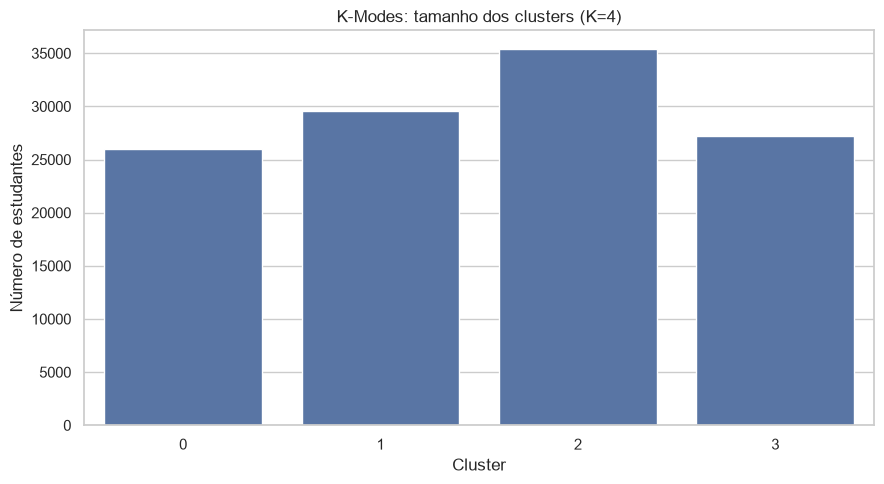


Arquivos CSV salvos com sucesso.


In [14]:

import pandas as pd
import numpy as np
from kmodes.kmodes import KModes
import matplotlib.pyplot as plt
import seaborn as sns

# ============================================================
# 1. DEFINIR O NÚMERO DE CLUSTERS
# ============================================================

K = 4
RANDOM_STATE = 42

# ============================================================
# 2. PREPARAR OS DADOS
# ============================================================

# Considere que seu DataFrame original se chama df.
# X deve conter somente as variáveis utilizadas no clustering.
# Exemplo:
# X = df.copy()

X = X.copy()

# Converter todas as variáveis para categóricas (strings)
X = X.astype("string")

# Tratar valores ausentes como uma categoria explícita
X = X.fillna("AUSENTE")

# Garantir que todas as colunas estejam em formato string
X = X.astype(str)

# Remover colunas constantes, se existirem
colunas_constantes = [
    col for col in X.columns if X[col].nunique() <= 1
]

if colunas_constantes:
    print("Colunas removidas por serem constantes:",
          colunas_constantes)
    X = X.drop(columns=colunas_constantes)

# Verificações
if X.empty:
    raise ValueError("Não há variáveis disponíveis para clustering.")

if len(X) <= K:
    raise ValueError("O número de observações deve ser maior que K.")

print("Número de estudantes:", len(X))
print("Número de variáveis:", X.shape[1])
print("Número de clusters:", K)

# ============================================================
# 3. EXECUTAR O K-MODES
# ============================================================

modelo_kmodes = KModes(
    n_clusters=K,
    init="Huang",
    n_init=5,
    max_iter=100,
    random_state=RANDOM_STATE,
    verbose=1
)

clusters = modelo_kmodes.fit_predict(X)

# Adicionar o cluster a cada estudante
df_resultado = df.loc[X.index].copy()
df_resultado["cluster"] = clusters

# ============================================================
# 4. TAMANHO E DISTRIBUIÇÃO DOS CLUSTERS
# ============================================================

tamanhos = (
    df_resultado["cluster"]
    .value_counts()
    .sort_index()
)

resumo_clusters = pd.DataFrame({
    "cluster": tamanhos.index,
    "n_estudantes": tamanhos.values,
    "percentual": (
        tamanhos.values / len(df_resultado) * 100
    ).round(2)
})

print("\nRESUMO DOS CLUSTERS")
print(resumo_clusters.to_string(index=False))

# ============================================================
# 5. MODAS DE CADA CLUSTER
# ============================================================

# Protótipos: categoria modal de cada variável em cada cluster
modas_clusters = pd.DataFrame(
    modelo_kmodes.cluster_centroids_,
    columns=X.columns
)

modas_clusters.index.name = "cluster"

print("\nMODAS DOS CLUSTERS")
print(modas_clusters.to_string())

# ============================================================
# 6. CUSTO FINAL DO MODELO
# ============================================================

print("\nCUSTO FINAL:", modelo_kmodes.cost_)
print("Número de iterações:", modelo_kmodes.n_iter_)

# ============================================================
# 7. GRÁFICO DO TAMANHO DOS CLUSTERS
# ============================================================

plt.figure(figsize=(9, 5))

sns.barplot(
    data=resumo_clusters,
    x="cluster",
    y="n_estudantes"
)

plt.title(f"K-Modes: tamanho dos clusters (K={K})")
plt.xlabel("Cluster")
plt.ylabel("Número de estudantes")
plt.tight_layout()
plt.show()

# ============================================================
# 8. SALVAR RESULTADOS
# ============================================================

df_resultado.to_csv(
    f"pense2024_kmodes_K{K}_estudantes.csv",
    index=False,
    encoding="utf-8-sig"
)

resumo_clusters.to_csv(
    f"pense2024_kmodes_K{K}_resumo.csv",
    index=False,
    encoding="utf-8-sig"
)

modas_clusters.to_csv(
    f"pense2024_kmodes_K{K}_modas.csv",
    encoding="utf-8-sig"
)

print("\nArquivos CSV salvos com sucesso.")
